# 03 · Segmentación de clientes (RFM + K-Means)

**Pregunta de negocio 2:** ¿qué tipos de clientes hay?

Datos: una fila por cliente con al menos un pedido completado, creada con `tabla_rfm()` de
`src/features.py`:

- **R**ecencia: días desde su último pedido completado hasta la fecha de corte.
- **F**recuencia: número de pedidos completados.
- **M**onetario: gasto total en pedidos completados (€).

> Requisito: haber ejecutado `python src/generar_datos.py` y `python src/limpieza.py`.
>
> **Regla del notebook:** el tipo real de cada cliente (`_verdad_clientes.csv`) **solo** se usa en la
> sección 9. Todo lo anterior (variables, k, nombres de los segmentos) se decide sin mirarlo, como en
> una empresa real, donde esa verdad no existe.

## 0. Configuración y carga

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# El notebook se ejecuta desde notebooks/: src está en ../src
RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ / "src"))
from features import clientes_sin_compras, tabla_rfm  # noqa: E402

SEMILLA = 42
CARPETA_IMG = RAIZ / "docs" / "img"
CARPETA_IMG.mkdir(parents=True, exist_ok=True)
CARPETA_MODELOS = RAIZ / "models"
CARPETA_MODELOS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
AZUL, NARANJA, VERDE_AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)


def euros(valor, decimales=0):
    """12345.6 -> '12.346 €' (formato español)."""
    texto = f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{texto} €"


def num(valor, decimales=2):
    """1234.567 -> '1.234,57' (número en formato español, sin unidad)."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


FORMATO_EUROS = mticker.FuncFormatter(lambda valor, _pos: euros(valor))


def guardar(fig, nombre):
    """Guarda la figura en docs/img/segmentacion_<nombre>.png.

    metadata={"Software": None} quita la versión de matplotlib del PNG: con los mismos datos,
    el archivo es idéntico byte a byte entre ejecuciones.
    """
    fig.savefig(CARPETA_IMG / f"segmentacion_{nombre}.png", dpi=120, bbox_inches="tight",
                metadata={"Software": None})

In [2]:
rfm = tabla_rfm()
RFM = ["recencia_dias", "frecuencia", "monetario"]
print(f"Fecha de corte: {rfm.attrs['fecha_corte']} (el día siguiente al último pedido de la BD)")
print(f"Clientes con al menos un pedido completado: {len(rfm)}")
print(f"Clientes sin ningún pedido completado (fuera del análisis): {rfm.attrs['n_clientes_sin_compras']}")
rfm.drop(columns="id_cliente").describe().round(1)

Fecha de corte: 2026-11-01 (el día siguiente al último pedido de la BD)
Clientes con al menos un pedido completado: 474
Clientes sin ningún pedido completado (fuera del análisis): 19


,recencia_dias,frecuencia,monetario,antiguedad_dias,ticket_medio
count,474.0,474.0,474.0,474.0,474.0
mean,163.9,13.8,1863.6,467.8,137.5
std,202.5,17.2,2410.8,173.6,117.8
min,1.0,1.0,9.1,24.0,9.1
25%,16.2,3.0,427.7,362.5,94.9
50%,59.0,7.5,961.6,492.0,123.5
75%,223.5,16.8,2298.6,612.8,154.7
max,703.0,115.0,16635.9,729.0,2205.3


**Lectura:** hay 474 clientes con al menos un pedido completado. La fecha de corte es el
2026-11-01, el día siguiente al último pedido. Los 19 clientes sin ningún pedido completado se
quedan fuera del K-Means: no tienen recencia ni gasto, y meterlos con valores inventados crearía
un grupo artificial. Aparecen en el CSV final como "Sin compras completadas".

En las tres variables RFM la media está muy por encima de la mediana. Frecuencia: media de 13,8
pedidos y mediana de 7,5. Monetario: media de 1.863,6 € y mediana de 961,6 €, con un máximo de
16.635,9 €. Es la primera señal de asimetría.

## 1. Por qué transformar las variables

K-Means agrupa por **distancias**. Dos problemas lo pueden estropear:

1. **Asimetría:** si una variable tiene una cola larga (unos pocos clientes con valores enormes),
   esos pocos clientes quedan "lejísimos" de todos y el algoritmo gasta grupos en ellos.
2. **Escala:** recencia va de 1 a ~700 días, frecuencia de 1 a ~100 pedidos y monetario de 9 a
   ~17.000 €. Sin igualar escalas, la variable con números más grandes decide sola las distancias
   (es lo mismo que pasaba con las medidas en cm del ejercicio de Iris).

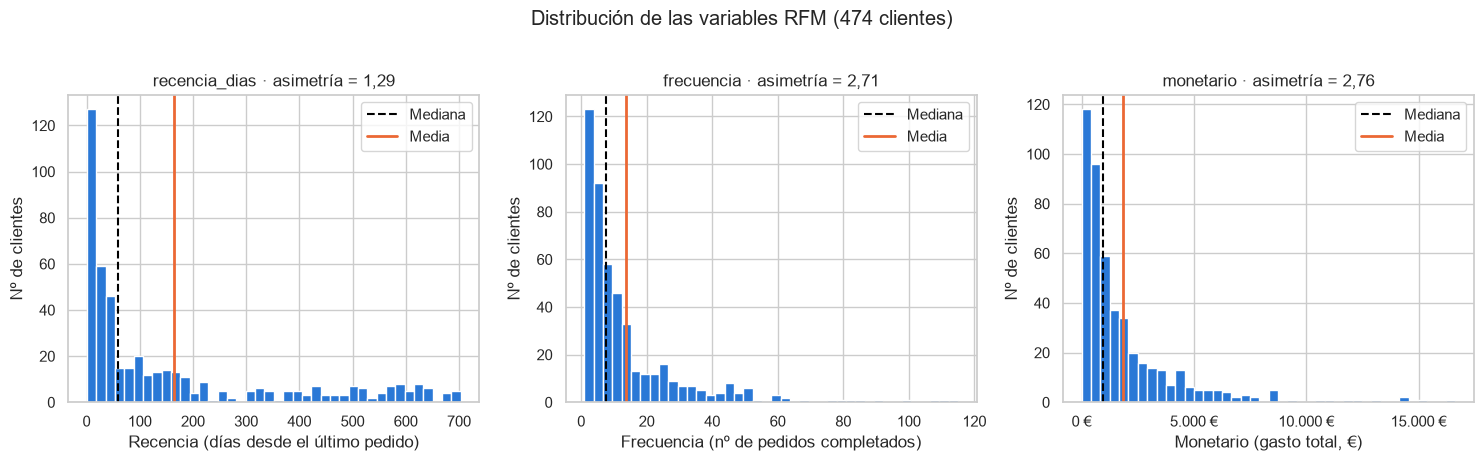

,asimetría original,asimetría con log1p,media,mediana
recencia_dias,1.29,1.29,163.92,59.0
frecuencia,2.71,0.33,13.80,7.5
monetario,2.76,-0.51,1863.63,961.6


In [3]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
etiquetas = {"recencia_dias": "Recencia (días desde el último pedido)",
             "frecuencia": "Frecuencia (nº de pedidos completados)",
             "monetario": "Monetario (gasto total, €)"}
for ax, var in zip(ejes, RFM):
    ax.hist(rfm[var], bins=40, color=AZUL, edgecolor="white")
    ax.axvline(rfm[var].median(), color="black", linestyle="--", linewidth=1.5, label="Mediana")
    ax.axvline(rfm[var].mean(), color=NARANJA, linewidth=2, label="Media")
    ax.set_title(f"{var} · asimetría = {num(rfm[var].skew())}")
    ax.set_xlabel(etiquetas[var])
    ax.set_ylabel("Nº de clientes")
    ax.legend()
ejes[2].xaxis.set_major_locator(mticker.MultipleLocator(5000))
ejes[2].xaxis.set_major_formatter(FORMATO_EUROS)
fig.suptitle("Distribución de las variables RFM (474 clientes)", y=1.02)
fig.tight_layout()
guardar(fig, "distribuciones")
plt.show()

asimetria = pd.DataFrame({
    "asimetría original": rfm[RFM].skew(),
    "asimetría con log1p": [rfm["recencia_dias"].skew(), np.log1p(rfm["frecuencia"]).skew(),
                            np.log1p(rfm["monetario"]).skew()],
    "media": rfm[RFM].mean(),
    "mediana": rfm[RFM].median(),
})
asimetria.round(2)

**Lectura:** las tres variables tienen **asimetría positiva**: muchos clientes con valores bajos y
una cola larga de pocos clientes con valores muy altos. La asimetría de frecuencia es 2,71 y la de
monetario 2,76, muy por encima de 1. Recencia también está sesgada (1,29), pero menos, y por eso
no se le aplica log: la instrucción del proyecto es aplicarlo a frecuencia y monetario.

Con `log1p`, la asimetría de frecuencia baja a 0,33 y la de monetario a −0,51: casi simétricas.

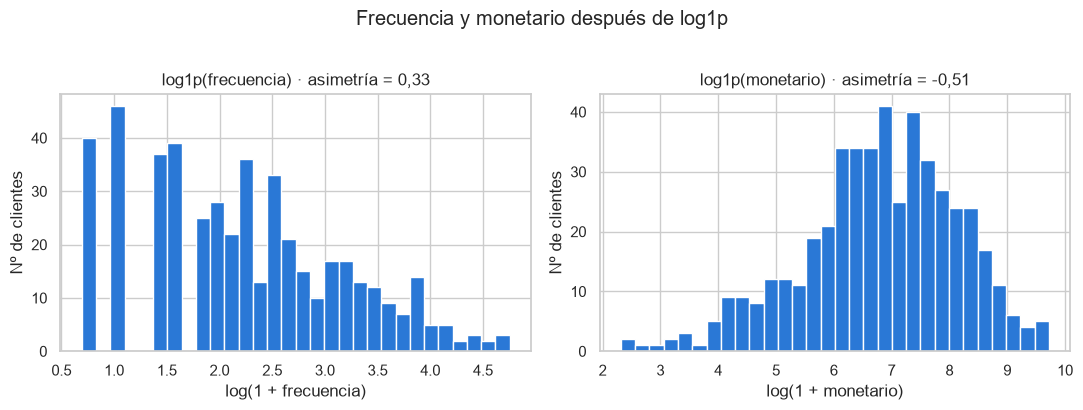

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, var in zip(ejes, ["frecuencia", "monetario"]):
    ax.hist(np.log1p(rfm[var]), bins=30, color=AZUL, edgecolor="white")
    ax.set_title(f"log1p({var}) · asimetría = {num(np.log1p(rfm[var]).skew())}")
    ax.set_xlabel(f"log(1 + {var})")
    ax.set_ylabel("Nº de clientes")
fig.suptitle("Frecuencia y monetario después de log1p", y=1.02)
fig.tight_layout()
plt.show()

**Lectura:** después de `log1p`, las dos variables tienen una forma mucho más compacta. Los
clientes más extremos (115 pedidos, 16.635,9 €) ya no quedan "a kilómetros" del resto, así que K-Means no
tiene que gastar un grupo entero en ellos.

## 2. Pipeline: log1p → StandardScaler → K-Means

- **`FunctionTransformer(np.log1p)`** solo sobre `frecuencia` y `monetario` (las dos muy asimétricas).
  Se aplica con un `ColumnTransformer`; `recencia_dias` pasa sin tocar. `log1p(x) = log(1 + x)` no da
  error con 0 y comprime la cola: 10 → 2,4; 100 → 4,6; 10.000 → 9,2.
- **`StandardScaler`:** cada variable pasa a media 0 y desviación 1, para que las tres pesen lo mismo.
- **`KMeans(n_init=10, random_state=42)`:** prueba 10 arranques distintos y se queda con el mejor.

Todo va en un `Pipeline` para guardar un único objeto que transforma y asigna segmentos a clientes
nuevos con los mismos pasos.

In [5]:
VARIABLES_LOG = ["frecuencia", "monetario"]


def crear_pipeline(variables: list, k: int, con_log: bool = True) -> Pipeline:
    """Pipeline de segmentación. con_log=False quita el log1p (sección 7)."""
    pasos = []
    if con_log:
        log = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
        pasos.append(("log", ColumnTransformer(
            [("log1p", log, [v for v in variables if v in VARIABLES_LOG])],
            remainder="passthrough", verbose_feature_names_out=False)))
    pasos += [("escalar", StandardScaler()),
              ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=SEMILLA))]
    return Pipeline(pasos)


def transformar(pipeline: Pipeline, datos: pd.DataFrame) -> np.ndarray:
    """Los datos tal como los ve K-Means: todos los pasos del pipeline menos el último."""
    return pipeline[:-1].transform(datos)


def metricas_k(variables: list, ks=range(2, 11), con_log: bool = True) -> pd.DataFrame:
    """Inercia, silueta media y Davies-Bouldin para cada k."""
    filas = []
    for k in ks:
        p = crear_pipeline(variables, k, con_log).fit(rfm[variables])
        Z, etiquetas_k = transformar(p, rfm[variables]), p[-1].labels_
        filas.append({"k": k, "inercia": p[-1].inertia_,
                      "silueta": silhouette_score(Z, etiquetas_k),
                      "davies_bouldin": davies_bouldin_score(Z, etiquetas_k),
                      "tamaño mínimo": np.bincount(etiquetas_k).min()})
    return pd.DataFrame(filas).set_index("k")


CON_ANTIGUEDAD = RFM + ["antiguedad_dias"]
met_rfm = metricas_k(RFM)
met_ant = metricas_k(CON_ANTIGUEDAD)
comparacion_variables = pd.DataFrame({
    "silueta RFM": met_rfm["silueta"], "silueta RFM + antigüedad": met_ant["silueta"],
    "DB RFM": met_rfm["davies_bouldin"], "DB RFM + antigüedad": met_ant["davies_bouldin"],
})
print("Silueta: más alta = mejor | Davies-Bouldin (DB): más bajo = mejor")
print("k en que añadir antigüedad mejora la silueta:",
      list(comparacion_variables.index[comparacion_variables["silueta RFM + antigüedad"] > comparacion_variables["silueta RFM"]]))
print("k en que añadir antigüedad mejora Davies-Bouldin:",
      list(comparacion_variables.index[comparacion_variables["DB RFM + antigüedad"] < comparacion_variables["DB RFM"]]))
comparacion_variables.round(3)

Silueta: más alta = mejor | Davies-Bouldin (DB): más bajo = mejor
k en que añadir antigüedad mejora la silueta: [8]
k en que añadir antigüedad mejora Davies-Bouldin: [8]


,silueta RFM,silueta RFM + antigüedad,DB RFM,DB RFM + antigüedad
k,,,,
2,0.458,0.369,0.893,1.086
3,0.428,0.401,0.830,0.923
4,0.439,0.372,0.800,0.899
5,0.396,0.364,0.818,0.911
6,0.389,0.347,0.847,0.911
7,0.383,0.354,0.824,0.927
8,0.343,0.355,0.904,0.901
9,0.347,0.332,0.915,0.930
10,0.353,0.345,0.896,0.917


**¿Añadir `antiguedad_dias`?** No. Con antigüedad, la silueta baja y Davies-Bouldin sube para
casi todos los k (solo mejora en k = 8). Con k = 4: silueta de 0,439 sin antigüedad frente a 0,372
con ella, y Davies-Bouldin de 0,800 frente a 0,899. La antigüedad no separa grupos: reparte a los
clientes de forma bastante uniforme y "diluye" las distancias que sí separan (recencia, frecuencia
y gasto). **Decisión: solo R, F y M.**

## 3. Elegir k (de 2 a 10)

- **Codo (inercia):** la inercia es la suma de distancias² de cada cliente a su centroide. Siempre baja
  al añadir grupos; se busca el punto en que deja de bajar mucho (el "codo").
- **Silueta media** (de −1 a 1): compara, para cada cliente, la distancia a su grupo con la distancia
  al grupo vecino. Cerca de 1 = grupos compactos y bien separados; cerca de 0 = grupos que se solapan.
- **Davies-Bouldin** (≥ 0): media de lo "parecido" que es cada grupo a su grupo más cercano.
  **Más bajo es mejor.**

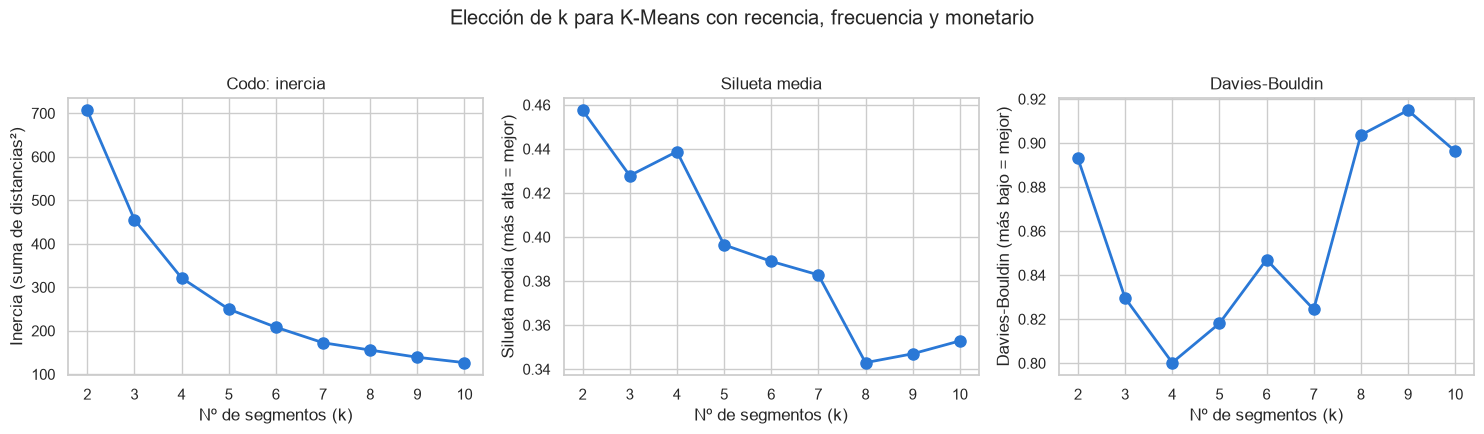

,inercia,silueta,davies_bouldin,tamaño mínimo,caída de inercia (%)
k,,,,,
2,706.936,0.458,0.893,186,NaN
3,455.592,0.428,0.830,118,35.554
4,321.524,0.439,0.800,69,29.427
5,249.729,0.396,0.818,58,22.330
6,208.233,0.389,0.847,29,16.617
7,172.547,0.383,0.824,16,17.138
8,155.666,0.343,0.904,21,9.784
9,139.155,0.347,0.915,16,10.607
10,126.715,0.353,0.896,15,8.940


In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.2))
paneles = [("inercia", "Inercia (suma de distancias²)", "Codo: inercia"),
           ("silueta", "Silueta media (más alta = mejor)", "Silueta media"),
           ("davies_bouldin", "Davies-Bouldin (más bajo = mejor)", "Davies-Bouldin")]
for ax, (col, etiqueta_y, titulo) in zip(ejes, paneles):
    ax.plot(met_rfm.index, met_rfm[col], marker="o", color=AZUL, linewidth=2, markersize=8)
    ax.set_title(titulo)
    ax.set_xlabel("Nº de segmentos (k)")
    ax.set_ylabel(etiqueta_y)
    ax.set_xticks(list(met_rfm.index))
fig.suptitle("Elección de k para K-Means con recencia, frecuencia y monetario", y=1.03)
fig.tight_layout()
guardar(fig, "eleccion_k")
plt.show()

met_rfm["caída de inercia (%)"] = -100 * met_rfm["inercia"].pct_change()
met_rfm.round(3)

**Elección: k = 4.**

- **Davies-Bouldin:** k = 4 es el mínimo de todo el rango (0,800).
- **Silueta:** k = 2 tiene la más alta (0,458), pero k = 4 está muy cerca (0,439) y por encima de
  k = 3 (0,428). A partir de k = 5 cae (0,396 o menos).
- **Codo:** la inercia cae un 35,6 % de 2 a 3 grupos y un 29,4 % de 3 a 4. De 4 a 5 cae menos
  (22,3 %) y a partir de ahí, cada vez menos. El codo está en 3–4.
- **Negocio:** k = 2 solo diría "buenos" y "malos" clientes, y eso no basta para decidir acciones.
  Con k = 4, el grupo más pequeño tiene 69 clientes, suficiente para una campaña.

No se ha forzado k = 3: las tres métricas apuntan a 4 o lo dejan como opción razonable.

In [7]:
K = 4
pipeline = crear_pipeline(RFM, K).fit(rfm[RFM])
Z = transformar(pipeline, rfm[RFM])
rfm["segmento"] = pipeline[-1].labels_
print(f"k = {K}: silueta = {silhouette_score(Z, rfm['segmento']):.3f}, "
      f"Davies-Bouldin = {davies_bouldin_score(Z, rfm['segmento']):.3f}")
print("Clientes por segmento:", rfm["segmento"].value_counts().sort_index().to_dict())

k = 4: silueta = 0.439, Davies-Bouldin = 0.800
Clientes por segmento: {0: 204, 1: 74, 2: 127, 3: 69}


## 4. Perfil de cada segmento

Los centroides de K-Means están en unidades transformadas (log y desviaciones típicas), que no se
entienden. Por eso el perfil se calcula con los **datos originales** de los clientes de cada segmento.

In [8]:
def perfil(datos: pd.DataFrame, columna: str) -> pd.DataFrame:
    """Medias y medianas en unidades originales, % de clientes y % de ingresos por segmento."""
    g = datos.groupby(columna)
    tabla = pd.concat([
        g[RFM + ["antiguedad_dias", "ticket_medio"]].median().add_prefix("mediana_"),
        g[RFM].mean().add_prefix("media_"),
        g.size().rename("clientes"),
        (100 * g.size() / len(datos)).rename("% clientes"),
        (100 * g["monetario"].sum() / datos["monetario"].sum()).rename("% ingresos"),
    ], axis=1)
    return tabla


perfil_kmeans = perfil(rfm, "segmento")
perfil_kmeans.round(1)

,mediana_recencia_dias,mediana_frecuencia,mediana_monetario,mediana_antiguedad_dias,mediana_ticket_medio,media_recencia_dias,media_frecuencia,media_monetario,clientes,% clientes,% ingresos
segmento,,,,,,,,,,,
0,42.0,7.0,878.4,439.0,126.7,68.9,7.6,1046.0,204,43.0,24.2
1,292.0,1.0,109.3,327.5,65.6,278.3,1.7,137.1,74,15.6,1.1
2,14.0,28.0,3737.7,620.0,129.5,35.3,34.9,4616.7,127,26.8,66.4
3,580.0,4.0,550.7,593.0,133.9,559.1,6.1,1065.4,69,14.6,8.3


**Lectura de los perfiles** (medianas, en unidades originales):

- **Segmento 2:** recencia de 14 días, 28 pedidos y 3.737,7 € de gasto. Compran mucho y hace poco.
- **Segmento 0:** recencia de 42 días, 7 pedidos y 878,4 €. Siguen comprando, pero mucho menos.
- **Segmento 1:** recencia de 292 días, **1 pedido** y 109,3 €. Compraron una vez y no volvieron.
- **Segmento 3:** recencia de **580 días**, 4 pedidos y 550,7 €. Compraron varias veces, pero hace
  más de año y medio que no vuelven.

Los nombres se ponen con las reglas de la celda siguiente, a partir de estas medianas.

In [9]:
def nombrar_segmentos(perfil_seg: pd.DataFrame) -> dict:
    """Pone nombre a cada segmento a partir de su perfil (medianas), con reglas explícitas.

    1. El de mayor gasto mediano -> "Fieles".
    2. De los demás, el de compra más reciente -> "Habituales".
    3. De los dos restantes, el de menos pedidos -> "Compra única"; el otro -> "Perdidos".
    """
    resto = perfil_seg.copy()
    nombres = {}
    for nombre, columna, funcion in [("Fieles", "mediana_monetario", "idxmax"),
                                     ("Habituales", "mediana_recencia_dias", "idxmin"),
                                     ("Compra única", "mediana_frecuencia", "idxmin")]:
        segmento = getattr(resto[columna], funcion)()
        nombres[segmento] = nombre
        resto = resto.drop(segmento)
    nombres[resto.index[0]] = "Perdidos"
    return nombres


NOMBRES = nombrar_segmentos(perfil_kmeans)
ORDEN = ["Fieles", "Habituales", "Compra única", "Perdidos"]
COLORES = dict(zip(ORDEN, [AZUL, NARANJA, VERDE_AGUA, AMARILLO]))
rfm["nombre_segmento"] = rfm["segmento"].map(NOMBRES)

perfil_nombres = perfil(rfm, "nombre_segmento").loc[ORDEN]
# Comprobaciones de que los nombres encajan con el perfil
assert perfil_nombres["mediana_recencia_dias"].idxmax() in ("Perdidos", "Compra única")
assert perfil_nombres.loc["Compra única", "mediana_frecuencia"] == perfil_nombres["mediana_frecuencia"].min()
print("Nombres:", {int(k): v for k, v in sorted(NOMBRES.items())})
perfil_nombres.round(1)

Nombres: {0: 'Habituales', 1: 'Compra única', 2: 'Fieles', 3: 'Perdidos'}


,mediana_recencia_dias,mediana_frecuencia,mediana_monetario,mediana_antiguedad_dias,mediana_ticket_medio,media_recencia_dias,media_frecuencia,media_monetario,clientes,% clientes,% ingresos
nombre_segmento,,,,,,,,,,,
Fieles,14.0,28.0,3737.7,620.0,129.5,35.3,34.9,4616.7,127,26.8,66.4
Habituales,42.0,7.0,878.4,439.0,126.7,68.9,7.6,1046.0,204,43.0,24.2
Compra única,292.0,1.0,109.3,327.5,65.6,278.3,1.7,137.1,74,15.6,1.1
Perdidos,580.0,4.0,550.7,593.0,133.9,559.1,6.1,1065.4,69,14.6,8.3


**Los cuatro segmentos:**

| Segmento | Clientes | % clientes | % ingresos | Recencia (mediana) | Pedidos (mediana) | Gasto (mediana) |
|---|---:|---:|---:|---:|---:|---:|
| **Fieles** | 127 | 26,8 % | 66,4 % | 14 días | 28 | 3.737,7 € |
| **Habituales** | 204 | 43,0 % | 24,2 % | 42 días | 7 | 878,4 € |
| **Compra única** | 74 | 15,6 % | 1,1 % | 292 días | 1 | 109,3 € |
| **Perdidos** | 69 | 14,6 % | 8,3 % | 580 días | 4 | 550,7 € |

El ticket medio es parecido en Fieles, Habituales y Perdidos (126,7–133,9 € de mediana). **Lo que
distingue a los segmentos es cuántas veces compran y cuándo fue la última, no cuánto gastan por
pedido.** La excepción es Compra única (65,6 €): su único pedido suele ser pequeño.

## 5. Gráficos de los segmentos

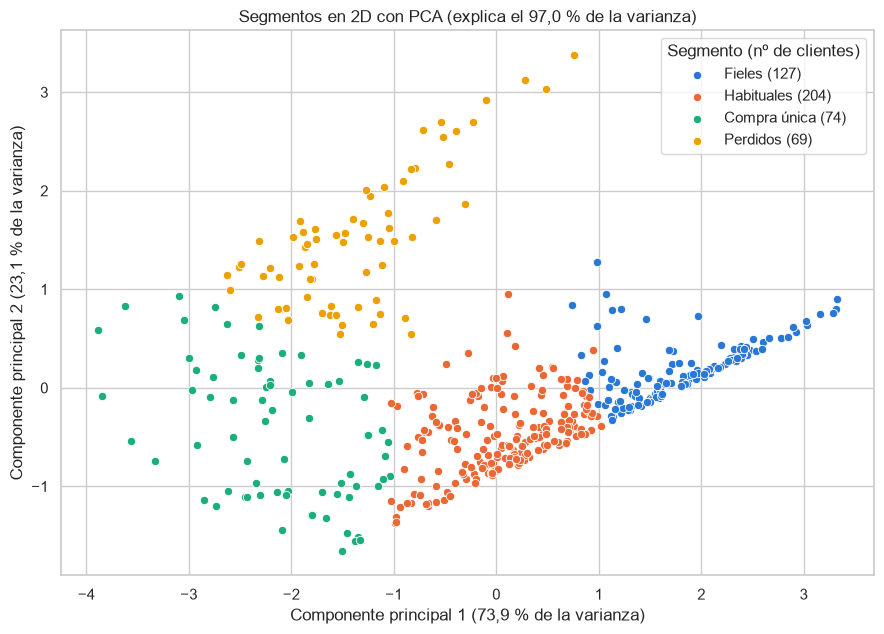

Varianza explicada: PC1 73,9 % + PC2 23,1 % = 97,0 %


,frecuencia,monetario,recencia_dias
PC1,0.63,0.63,-0.45
PC2,0.30,0.34,0.89


In [10]:
# PCA: resume las 3 variables transformadas en 2 ejes para poder dibujarlas
pca = PCA(n_components=2, random_state=SEMILLA).fit(Z)
Z2 = pca.transform(Z)
var1, var2 = 100 * pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 6.5))
for nombre in ORDEN:
    filtro = (rfm["nombre_segmento"] == nombre).to_numpy()
    ax.scatter(Z2[filtro, 0], Z2[filtro, 1], s=36, color=COLORES[nombre], edgecolor="white",
               linewidth=0.6, label=f"{nombre} ({filtro.sum()})")
ax.set_title(f"Segmentos en 2D con PCA (explica el {num(var1 + var2, 1)} % de la varianza)")
ax.set_xlabel(f"Componente principal 1 ({num(var1, 1)} % de la varianza)")
ax.set_ylabel(f"Componente principal 2 ({num(var2, 1)} % de la varianza)")
ax.legend(title="Segmento (nº de clientes)")
fig.tight_layout()
guardar(fig, "pca")
plt.show()

print(f"Varianza explicada: PC1 {num(var1, 1)} % + PC2 {num(var2, 1)} % = {num(var1 + var2, 1)} %")
# Cargas: cuánto pesa cada variable (transformada) en cada componente
pd.DataFrame(pca.components_, columns=pipeline[:-1].get_feature_names_out(),
             index=["PC1", "PC2"]).round(2)

**Lectura del PCA:** el PCA busca las 2 direcciones que más varianza recogen de las 3 variables
(ya transformadas) y proyecta a cada cliente en ellas. Aquí esas 2 componentes explican el 97,0 %
de la varianza (73,9 % + 23,1 %), así que el dibujo 2D es casi fiel a los datos originales en 3D.

- **Componente 1:** frecuencia (0,63) y monetario (0,63) en positivo, recencia (−0,45) en negativo.
  Es el **"valor" del cliente**: a la derecha, los Fieles; a la izquierda, Compra única.
- **Componente 2:** sobre todo recencia (0,89). Arriba están los clientes que hace mucho que no
  compran: los Perdidos.

Los segmentos ocupan zonas distintas, pero **se tocan sin huecos entre ellos**: los clientes forman
un continuo, y K-Means lo corta en 4 partes. Esto explica la silueta moderada (0,439).

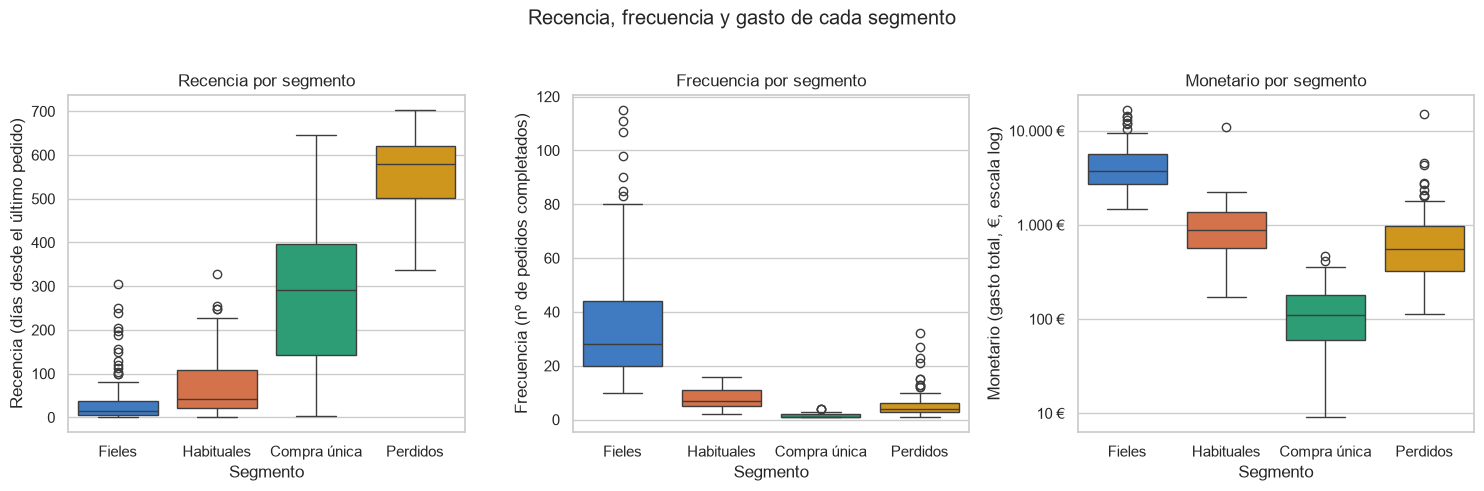

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, var in zip(ejes, RFM):
    sns.boxplot(data=rfm, x="nombre_segmento", y=var, hue="nombre_segmento", order=ORDEN,
                palette=COLORES, legend=False, ax=ax)
    ax.set_title(etiquetas[var].split(" (")[0] + " por segmento")
    ax.set_xlabel("Segmento")
    ax.set_ylabel(etiquetas[var])
ejes[2].set_yscale("log")
ejes[2].yaxis.set_major_formatter(FORMATO_EUROS)
ejes[2].set_ylabel("Monetario (gasto total, €, escala log)")
fig.suptitle("Recencia, frecuencia y gasto de cada segmento", y=1.02)
fig.tight_layout()
guardar(fig, "boxplots")
plt.show()

**Lectura de los boxplots:**

- **Recencia:** Fieles y Habituales compran hace poco (medianas de 14 y 42 días). Perdidos lleva
  580 días sin comprar y Compra única, 292, con mucha dispersión.
- **Frecuencia:** solo los Fieles tienen muchos pedidos (mediana de 28). Compra única se queda en 1.
- **Monetario** (escala log): cada segmento está casi un orden de magnitud por debajo del anterior,
  salvo Perdidos, que gastó más que Compra única (550,7 € frente a 109,3 €) porque llegó a repetir.

Hay puntos sueltos (círculos), por ejemplo algún Perdido o Habitual con un gasto muy por encima del de su grupo.
Son clientes con un pedido enorme: su gasto no encaja, pero su recencia y su frecuencia sí.

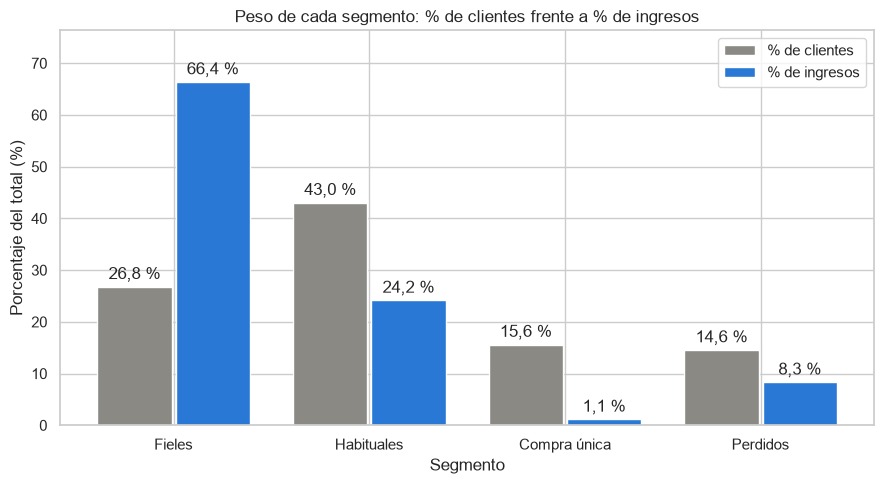

,% clientes,% ingresos
nombre_segmento,,
Fieles,26.8,66.4
Habituales,43.0,24.2
Compra única,15.6,1.1
Perdidos,14.6,8.3


In [12]:
reparto = perfil_nombres[["% clientes", "% ingresos"]]
x = np.arange(len(ORDEN))
fig, ax = plt.subplots(figsize=(9, 5))
barras_c = ax.bar(x - 0.2, reparto["% clientes"], width=0.38, color=GRIS, label="% de clientes")
barras_i = ax.bar(x + 0.2, reparto["% ingresos"], width=0.38, color=AZUL, label="% de ingresos")
for barras in (barras_c, barras_i):
    ax.bar_label(barras, labels=[f"{num(v, 1)} %" for v in barras.datavalues], padding=3)
ax.set_xticks(x, ORDEN)
ax.set_title("Peso de cada segmento: % de clientes frente a % de ingresos")
ax.set_xlabel("Segmento")
ax.set_ylabel("Porcentaje del total (%)")
ax.set_ylim(0, reparto.to_numpy().max() * 1.15)
ax.legend()
fig.tight_layout()
guardar(fig, "clientes_ingresos")
plt.show()
reparto.round(1)

**Lectura:** los **Fieles** son el 26,8 % de los clientes y generan el **66,4 % de los ingresos**.
Los **Habituales** son el grupo más grande (43,0 %), pero aportan el 24,2 %. **Compra única** es el
15,6 % de los clientes y solo el 1,1 % de los ingresos. Los **Perdidos** (14,6 %) generaron el 8,3 %:
es dinero que la tienda ya ha dejado de recibir.

## 6. Comparación con otros algoritmos

Del ejercicio de clase:

| Algoritmo | Qué grupos encuentra bien | Necesita |
|---|---|---|
| **K-Means** | Esféricos y de tamaño parecido | k |
| **Jerárquico (ward)** | Estructuras anidadas (grupos dentro de grupos) | Dónde cortar el árbol |
| **DBSCAN** | Formas irregulares; marca los puntos aislados como **ruido** | `eps` y `min_samples` |

Los tres trabajan sobre los mismos datos transformados (`Z`: log1p + estandarización).

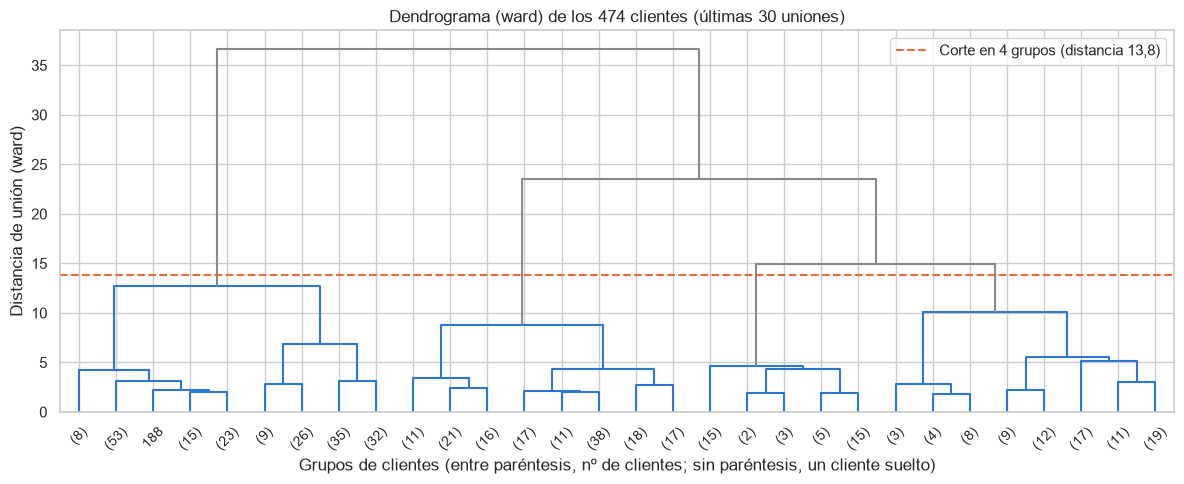

Distancia de unión de las 6 últimas uniones: [ 8.8 10.1 12.8 14.9 23.5 36.7]


seg_jerarquico,0,1,2,3
nombre_segmento,,,,
Fieles,127,0,0,0
Habituales,75,2,127,0
Compra única,0,12,22,40
Perdidos,0,69,0,0


In [13]:
# Jerárquico con ward: une en cada paso los dos grupos que menos aumentan la varianza interna
enlaces = linkage(Z, method="ward")
# Altura de corte para K grupos: a medio camino entre la unión que deja K grupos y la que deja K - 1
corte = (enlaces[-K, 2] + enlaces[-(K - 1), 2]) / 2
fig, ax = plt.subplots(figsize=(12, 5))
# Ramas en un solo color: los colores de los segmentos de K-Means se reservan para K-Means
dendrogram(enlaces, truncate_mode="lastp", p=30, color_threshold=corte,
           link_color_func=lambda _id: AZUL if enlaces[_id - len(Z), 2] < corte else GRIS, ax=ax)
ax.axhline(corte, color=NARANJA, linestyle="--", label=f"Corte en {K} grupos (distancia {num(corte, 1)})")
ax.set_title("Dendrograma (ward) de los 474 clientes (últimas 30 uniones)")
ax.set_xlabel("Grupos de clientes (entre paréntesis, nº de clientes; sin paréntesis, un cliente suelto)")
ax.set_ylabel("Distancia de unión (ward)")
ax.legend()
fig.tight_layout()
guardar(fig, "dendrograma")
plt.show()

jerarquico = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
rfm["seg_jerarquico"] = jerarquico.labels_
print("Distancia de unión de las 6 últimas uniones:", np.round(enlaces[-6:, 2], 1))
pd.crosstab(rfm["nombre_segmento"], rfm["seg_jerarquico"]).loc[ORDEN]

**Lectura del dendrograma:** cada unión es un punto en que dos grupos se juntan; cuanto más alta,
más distintos eran. Las últimas uniones están a 12,8, 14,9, 23,5 y 36,7. El mayor salto está
entre 23,5 y 36,7, lo que sugiere 2 grupos, y el siguiente entre 14,9 y 23,5 (3 grupos). Con el
corte en 4 grupos, el jerárquico se parece a K-Means solo en parte:

- Junta a los 127 Fieles con 75 Habituales (los más activos).
- Separa a Compra única en tres trozos (12, 22 y 40 clientes).
- Deja a los 69 Perdidos con 2 Habituales y 12 de Compra única.

Esto es lo esperado en datos sin grupos muy marcados: cada algoritmo corta el continuo por un
sitio algo distinto.

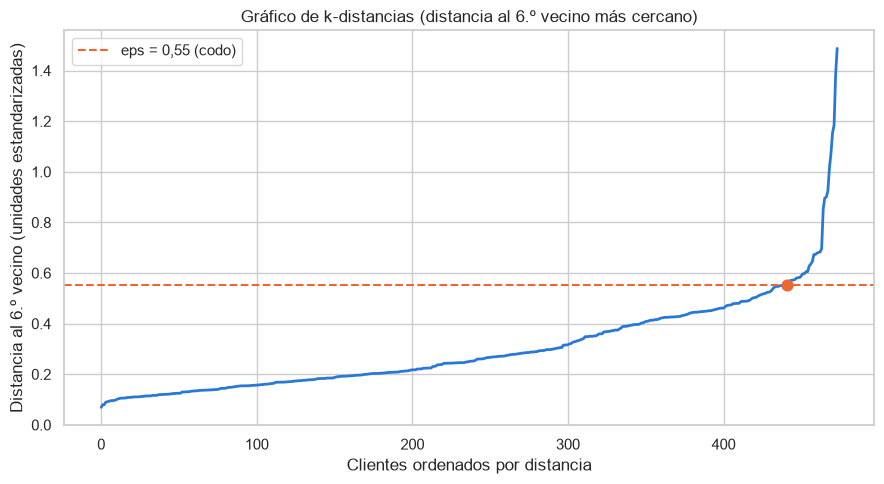

eps = 0.554, min_samples = 6
DBSCAN encuentra 1 grupos y marca 10 clientes como ruido (2,1 %)


seg_dbscan,0,ruido
nombre_segmento,,
Fieles,127,0
Habituales,202,2
Compra única,69,5
Perdidos,66,3


In [14]:
# DBSCAN: eps con el gráfico de k-distancias.
# min_samples = 2 × nº de variables = 6 (regla habitual). Para cada cliente se mira la distancia a
# su 6.º vecino más cercano (contándose a sí mismo); ordenadas, la curva "se dispara" donde empiezan
# los puntos aislados. El codo de esa curva es un buen eps.
MIN_MUESTRAS = 2 * Z.shape[1]
distancias, _ = NearestNeighbors(n_neighbors=MIN_MUESTRAS).fit(Z).kneighbors(Z)
k_dist = np.sort(distancias[:, -1])

# Codo = punto de la curva más alejado de la recta que une el primero y el último.
# Los dos ejes se pasan a [0, 1] para que el nº de clientes (0-474) no pese más que la distancia.
x_norm = np.arange(len(k_dist)) / (len(k_dist) - 1)
y_norm = (k_dist - k_dist[0]) / (k_dist[-1] - k_dist[0])
# La recta va de (0, 0) a (1, 1): la distancia de cada punto a ella es |x - y| / √2
alejamiento = np.abs(x_norm - y_norm) / np.sqrt(2)
codo = int(np.argmax(alejamiento))
EPS = float(k_dist[codo])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_dist, color=AZUL, linewidth=2)
ax.axhline(EPS, color=NARANJA, linestyle="--", label=f"eps = {num(EPS, 2)} (codo)")
ax.scatter([codo], [EPS], color=NARANJA, s=60, zorder=3)
ax.set_title(f"Gráfico de k-distancias (distancia al {MIN_MUESTRAS}.º vecino más cercano)")
ax.set_xlabel("Clientes ordenados por distancia")
ax.set_ylabel(f"Distancia al {MIN_MUESTRAS}.º vecino (unidades estandarizadas)")
ax.legend()
fig.tight_layout()
guardar(fig, "kdistancias")
plt.show()

dbscan = DBSCAN(eps=EPS, min_samples=MIN_MUESTRAS).fit(Z)
rfm["seg_dbscan"] = dbscan.labels_
ruido = rfm["seg_dbscan"] == -1
print(f"eps = {EPS:.3f}, min_samples = {MIN_MUESTRAS}")
print(f"DBSCAN encuentra {rfm['seg_dbscan'].max() + 1} grupos y marca {ruido.sum()} clientes como ruido "
      f"({num(100 * ruido.mean(), 1)} %)")
pd.crosstab(rfm["nombre_segmento"], rfm["seg_dbscan"].replace(-1, "ruido")).loc[ORDEN]

**Lectura de DBSCAN:** el codo del gráfico de k-distancias da eps = 0,554. Con ese eps, DBSCAN
encuentra **1 solo grupo** con todos los demás clientes y marca **10 como ruido (2,1 %)**: los más aislados,
repartidos entre Habituales (2), Compra única (5) y Perdidos (3).

Con eps más pequeño (0,416) salen 7 grupos, pero con un 13,3 % de los clientes como ruido; con eps
mayor sigue habiendo 1 grupo. **No hay zonas densas separadas por zonas vacías**, que es lo que
DBSCAN necesita. Es la misma conclusión del PCA: los clientes forman un continuo. DBSCAN sí sirve
para otra cosa: los 10 puntos de ruido son clientes atípicos que conviene revisar (lo hará la S8).

In [15]:
# Sensibilidad de DBSCAN a eps: cuántos grupos y cuánto ruido con otros valores
filas = []
for factor in [0.75, 1.0, 1.25, 1.5]:
    etiquetas_db = DBSCAN(eps=EPS * factor, min_samples=MIN_MUESTRAS).fit_predict(Z)
    filas.append({"eps": EPS * factor, "grupos": etiquetas_db.max() + 1,
                  "% ruido": 100 * (etiquetas_db == -1).mean()})
pd.DataFrame(filas).round(3)

,eps,grupos,% ruido
0,0.416,7,13.291
1,0.554,1,2.110
2,0.693,1,1.266
3,0.831,1,1.055


In [16]:
# Tabla comparativa. La silueta de DBSCAN se calcula sin los puntos de ruido (no son un grupo);
# si encuentra menos de 2 grupos, la silueta no se puede calcular.
def silueta_sin_ruido(etiquetas_m) -> float:
    etiquetas_m = np.asarray(etiquetas_m)
    validos = etiquetas_m != -1
    if len(set(etiquetas_m[validos])) < 2:
        return np.nan
    return silhouette_score(Z[validos], etiquetas_m[validos])


metodos = {"K-Means": rfm["segmento"], "Jerárquico (ward)": rfm["seg_jerarquico"], "DBSCAN": rfm["seg_dbscan"]}
resumen_metodos = pd.DataFrame({
    "grupos": {m: len(set(e) - {-1}) for m, e in metodos.items()},
    "clientes como ruido": {m: int((e == -1).sum()) for m, e in metodos.items()},
    "silueta": {m: silueta_sin_ruido(e) for m, e in metodos.items()},
})
ari = pd.DataFrame({a: {b: adjusted_rand_score(metodos[a], metodos[b]) for b in metodos} for a in metodos})
print("Resumen por método:")
display(resumen_metodos.round(3))
print("Adjusted Rand Index entre métodos (1 = mismas agrupaciones, 0 = como al azar):")
ari.round(3)

Resumen por método:


,grupos,clientes como ruido,silueta
K-Means,4,0,0.439
Jerárquico (ward),4,0,0.412
DBSCAN,1,10,NaN


Adjusted Rand Index entre métodos (1 = mismas agrupaciones, 0 = como al azar):


,K-Means,Jerárquico (ward),DBSCAN
K-Means,1.000,0.481,0.012
Jerárquico (ward),0.481,1.000,0.017
DBSCAN,0.012,0.017,1.000


**Comparación:**

| Método | Grupos | Ruido | Silueta | ARI con K-Means |
|---|---:|---:|---:|---:|
| **K-Means** | 4 | 0 | **0,439** | 1 |
| Jerárquico (ward) | 4 | 0 | 0,412 | 0,481 |
| DBSCAN | 1 | 10 | no calculable (1 grupo) | 0,012 |

El **Adjusted Rand Index (ARI)** mide cuánto se parecen dos agrupaciones: 1 = idénticas, 0 = lo que
saldría al azar. K-Means y el jerárquico coinciden a medias (0,481); DBSCAN no se parece a ninguno
(0,012 y 0,017), porque casi no separa nada.

**Por qué K-Means en estos datos:** tiene la mejor silueta, sus grupos se explican con una frase y,
al ser un continuo sin formas raras, no hace falta la flexibilidad de DBSCAN. Además, K-Means
asigna clientes nuevos con `predict` (el jerárquico no lo permite). El jerárquico confirma que hay
estructura en 2–4 grupos, y DBSCAN, que no hay grupos densos aislados.

## 7. Sensibilidad: el mismo K-Means sin log1p

Mismo pipeline y mismo k, pero quitando el `log1p`: solo `StandardScaler` → `KMeans`.

In [17]:
pipeline_sin_log = crear_pipeline(RFM, K, con_log=False).fit(rfm[RFM])
Z_sin_log = transformar(pipeline_sin_log, rfm[RFM])
rfm["segmento_sin_log"] = pipeline_sin_log[-1].labels_

print(f"Silueta sin log: {silhouette_score(Z_sin_log, rfm['segmento_sin_log']):.3f} "
      f"(con log: {silhouette_score(Z, rfm['segmento']):.3f})")
print(f"Adjusted Rand Index con log frente a sin log: {adjusted_rand_score(rfm['segmento'], rfm['segmento_sin_log']):.3f}")
pd.crosstab(rfm["nombre_segmento"], rfm["segmento_sin_log"], margins=True, margins_name="Total").loc[ORDEN + ["Total"]]

Silueta sin log: 0.577 (con log: 0.439)
Adjusted Rand Index con log frente a sin log: 0.503


segmento_sin_log,0,1,2,3,Total
nombre_segmento,,,,,
Fieles,41,10,0,76,127
Habituales,202,0,1,1,204
Compra única,37,0,37,0,74
Perdidos,0,0,68,1,69
Total,280,10,106,78,474


In [18]:
# Perfil de los segmentos sin log (en unidades originales)
perfil(rfm, "segmento_sin_log").round(1)

,mediana_recencia_dias,mediana_frecuencia,mediana_monetario,mediana_antiguedad_dias,mediana_ticket_medio,media_recencia_dias,media_frecuencia,media_monetario,clientes,% clientes,% ingresos
segmento_sin_log,,,,,,,,,,,
0,46.0,7.0,886.0,429.5,122.3,75.6,8.4,1100.9,280,59.1,34.9
1,7.0,87.5,11959.6,700.0,136.4,9.2,91.2,11902.2,10,2.1,13.5
2,517.0,3.0,339.8,547.5,118.5,505.8,4.5,609.3,106,22.4,7.3
3,12.0,34.0,4444.0,574.5,128.6,36.3,35.9,5019.3,78,16.5,44.3


In [19]:
# ¿Qué variable manda? Para cada variable, qué parte de su varianza explican los segmentos
# (R² = varianza entre grupos / varianza total). Si una variable tiene R² alto, los grupos se han
# formado sobre todo con ella.
def r2_por_variable(etiquetas_m) -> pd.Series:
    datos = rfm[RFM]
    medias_grupo = datos.groupby(np.asarray(etiquetas_m)).transform("mean")
    return 1 - ((datos - medias_grupo) ** 2).sum() / ((datos - datos.mean()) ** 2).sum()


# Valor estandarizado máximo de cada variable: cuántas desviaciones típicas se aleja el cliente más extremo
z_max = pd.DataFrame({"z máximo sin log": Z_sin_log.max(axis=0)}, index=RFM)
z_max["z máximo con log"] = pd.Series(Z.max(axis=0), index=pipeline[:-1].get_feature_names_out())
pd.concat([z_max, pd.DataFrame({"R² con log": r2_por_variable(rfm["segmento"]),
                                "R² sin log": r2_por_variable(rfm["segmento_sin_log"])})], axis=1).round(3)

,z máximo sin log,z máximo con log,R² con log,R² sin log
recencia_dias,2.665,2.665,0.809,0.830
frecuencia,5.888,2.650,0.567,0.824
monetario,6.134,2.164,0.496,0.769


**Lectura de la sensibilidad:**

- **Sin log, los segmentos cambian mucho:** el ARI entre las dos versiones es 0,503. Aparece un grupo
  de **solo 10 clientes** con 87,5 pedidos y 11.959,6 € de mediana (el 13,5 % de los ingresos), y los
  127 Fieles se reparten: 76 en un grupo "muy fieles", 41 con los Habituales y 10 en ese grupo de 10.
  Además, 37 clientes de Compra única pasan al grupo grande de 280 clientes.
- **Por qué domina monetario (y frecuencia):** estandarizar no corrige la asimetría. Sin log, el
  cliente más extremo está a 6,13 desviaciones típicas en monetario y a 5,89 en frecuencia, frente a
  2,67 en recencia. K-Means minimiza distancias², y un cliente a 6 desviaciones "pesa" muchísimo: le
  compensa dedicar un grupo entero a esos 10 clientes. Con log, el máximo baja a 2,16 en monetario y
  2,65 en frecuencia, y las tres variables pesan parecido.
- **Qué parte de cada variable explican los grupos (R²):** sin log, 0,769 en monetario y 0,824 en
  frecuencia; con log, 0,496 y 0,567. Sin log, los grupos se forman sobre todo con el volumen de
  compra; con log, la recencia (0,809) también pesa.
- La silueta sin log es más alta (0,577 frente a 0,439), pero **no son comparables**: cada una se
  mide en su propio espacio de variables, y en el espacio sin log un grupo diminuto y muy alejado
  sube la silueta sin que los segmentos sean más útiles.

**Decisión:** se mantiene el modelo **con log**. Sus 4 segmentos tienen tamaños útiles (de 69 a 204
clientes) y no dependen de una decena de clientes extremos.

## 8. Acciones de negocio por segmento

| Segmento | Acciones |
|---|---|
| **Fieles** (127 clientes, 66,4 % de los ingresos) | 1) Programa de fidelización (envío gratis, acceso anticipado a novedades) para que no se vayan: son dos tercios de los ingresos. 2) Vigilar su recencia: su mediana es de 14 días, así que un Fiel que lleva varios meses sin comprar debe activar un aviso y un contacto personal. |
| **Habituales** (204 clientes, 24,2 %) | 1) Venta cruzada con recomendaciones según lo que ya compran, para subir la frecuencia (7 pedidos) hacia la de los Fieles. 2) Cupón por volumen ("a partir del 3.er pedido del trimestre, 10 %"). |
| **Compra única** (74 clientes, 1,1 %) | 1) Email de "segunda compra" con un descuento pequeño poco después del primer pedido: el reto es que vuelvan una vez. 2) Encuesta corta para saber por qué no volvieron. No conviene gastar mucho: su ticket es bajo (65,6 € de mediana). |
| **Perdidos** (69 clientes, 8,3 %) | 1) Campaña de reactivación ("te echamos de menos") con una oferta, solo a los que más gastaron. 2) Si no responden en 2–3 envíos, dejar de enviar para no gastar ni dañar la reputación del dominio de email. |

## Guardar el modelo y los segmentos

In [20]:
# Pipeline final con todo lo necesario para usarlo. "datos_hasta" es el último día con pedidos
# (no la fecha de hoy): con los mismos datos, el archivo es idéntico entre ejecuciones.
paquete = {
    "pipeline": pipeline,
    "variables": RFM,
    "nombres_segmentos": {int(k): v for k, v in sorted(NOMBRES.items())},
    "fecha_corte": rfm.attrs["fecha_corte"],
    "datos_hasta": str((pd.Timestamp(rfm.attrs["fecha_corte"]) - pd.Timedelta(days=1)).date()),
}
ruta_modelo = CARPETA_MODELOS / "segmentacion_kmeans.joblib"
joblib.dump(paquete, ruta_modelo)
print("Modelo guardado en", ruta_modelo.relative_to(RAIZ))

# Comprobación: se carga y asigna los mismos segmentos, también a clientes "nuevos"
cargado = joblib.load(ruta_modelo)
assert (cargado["pipeline"].predict(rfm[cargado["variables"]]) == rfm["segmento"]).all()
ejemplo = pd.DataFrame({"recencia_dias": [10, 400], "frecuencia": [30, 1], "monetario": [4000, 80]})
for fila, seg in zip(ejemplo.itertuples(index=False), cargado["pipeline"].predict(ejemplo)):
    print(f"Recencia {fila.recencia_dias} días, {fila.frecuencia} pedidos, {euros(fila.monetario)} "
          f"→ {cargado['nombres_segmentos'][int(seg)]}")
print("datos_hasta =", cargado["datos_hasta"])

Modelo guardado en models\segmentacion_kmeans.joblib
Recencia 10 días, 30 pedidos, 4.000 € → Fieles
Recencia 400 días, 1 pedidos, 80 € → Compra única
datos_hasta = 2026-10-31


In [21]:
# Segmentos para el Power BI de la S10. Los clientes sin ningún pedido completado no entran en el
# K-Means, pero se incluyen con segmento -1 para que el informe tenga a todos los clientes.
sin_compras = clientes_sin_compras().assign(segmento=-1, nombre_segmento="Sin compras completadas")
segmentos_csv = (pd.concat([rfm[["id_cliente", "segmento", "nombre_segmento"]], sin_compras])
                 .sort_values("id_cliente").reset_index(drop=True))
ruta_csv = RAIZ / "data" / "processed" / "segmentos_clientes.csv"
segmentos_csv.to_csv(ruta_csv, index=False, encoding="utf-8")
print(f"Guardado {ruta_csv.relative_to(RAIZ)}: {len(segmentos_csv)} clientes")
segmentos_csv["nombre_segmento"].value_counts()

Guardado data\processed\segmentos_clientes.csv: 493 clientes


nombre_segmento
Habituales                 204
Fieles                     127
Compra única                74
Perdidos                    69
Sin compras completadas     19
Name: count, dtype: int64

## 9. ✅ Evaluación con la verdad (solo posible porque los datos son simulados)

> **Esta sección no se podría hacer en una empresa real:** nadie sabe el "tipo verdadero" de un
> cliente. Aquí lo sabemos porque el generador asignó a cada cliente un tipo oculto (fiel,
> ocasional o puntual). Es la **única** sección que lo usa, y solo para evaluar: los segmentos,
> k y los nombres ya están decididos.

Ojo: K-Means ha hecho **4** segmentos y la verdad tiene **3** tipos, así que no puede coincidir al
100 %. Para el % de coincidencia, a cada segmento se le asigna su tipo mayoritario.

In [22]:
verdad = pd.read_csv(RAIZ / "data" / "raw" / "_verdad_clientes.csv")
evaluacion = rfm.merge(verdad, on="id_cliente", how="left")
assert evaluacion["tipo_real"].notna().all()


def evaluar_con_verdad(columna: str) -> dict:
    """Crosstab, % de coincidencia (tipo mayoritario de cada segmento) y ARI."""
    tabla = pd.crosstab(evaluacion[columna], evaluacion["tipo_real"])
    mayoritario = tabla.idxmax(axis=1)
    acierto = evaluacion[columna].map(mayoritario) == evaluacion["tipo_real"]
    return {"tabla": tabla, "mayoritario": mayoritario, "acierto": acierto,
            "coincidencia": 100 * acierto.mean(),
            "ari": adjusted_rand_score(evaluacion["tipo_real"], evaluacion[columna])}


ev_log = evaluar_con_verdad("nombre_segmento")
ev_sin_log = evaluar_con_verdad("segmento_sin_log")
print("Distribución real de tipos:", evaluacion["tipo_real"].value_counts().to_dict())
print(f"CON log:  coincidencia {num(ev_log['coincidencia'], 1)} % | ARI {ev_log['ari']:.3f}")
print(f"SIN log:  coincidencia {num(ev_sin_log['coincidencia'], 1)} % | ARI {ev_sin_log['ari']:.3f}")
print("\nTipo mayoritario de cada segmento (con log):", ev_log["mayoritario"].to_dict())
ev_log["tabla"].loc[ORDEN]

Distribución real de tipos: {'ocasional': 237, 'puntual': 150, 'fiel': 87}
CON log:  coincidencia 79,1 % | ARI 0.405
SIN log:  coincidencia 81,4 % | ARI 0.490

Tipo mayoritario de cada segmento (con log): {'Compra única': 'puntual', 'Fieles': 'fiel', 'Habituales': 'ocasional', 'Perdidos': 'puntual'}


tipo_real,fiel,ocasional,puntual
nombre_segmento,,,
Fieles,74,50,3
Habituales,12,173,19
Compra única,1,14,59
Perdidos,0,0,69


In [23]:
print("Sin log: tipo mayoritario de cada segmento:", ev_sin_log["mayoritario"].to_dict())
ev_sin_log["tabla"]

Sin log: tipo mayoritario de cada segmento: {0: 'ocasional', 1: 'fiel', 2: 'puntual', 3: 'fiel'}


tipo_real,fiel,ocasional,puntual
segmento_sin_log,,,
0,22,216,42
1,10,0,0
2,0,1,105
3,55,20,3


In [24]:
# ¿Quién se confunde? Clientes cuyo tipo real no es el mayoritario de su segmento
evaluacion["acierto"] = ev_log["acierto"]
errores = evaluacion[~evaluacion["acierto"]]
print(f"Clientes mal clasificados (con log): {len(errores)} de {len(evaluacion)}")
pd.crosstab(errores["nombre_segmento"], errores["tipo_real"]).loc[[n for n in ORDEN if n in set(errores["nombre_segmento"])]]

Clientes mal clasificados (con log): 99 de 474


tipo_real,fiel,ocasional,puntual
nombre_segmento,,,
Fieles,0,50,3
Habituales,12,0,19
Compra única,1,14,0


In [25]:
# Perfil de los grupos de error más grandes frente a los aciertos del mismo tipo real
columnas = RFM + ["antiguedad_dias", "ticket_medio"]
grupos = (evaluacion.groupby(["tipo_real", "nombre_segmento"])[columnas].median()
          .join(evaluacion.groupby(["tipo_real", "nombre_segmento"]).size().rename("clientes")))
grupos.round(1)

recencia_dias  frecuencia  monetario  antiguedad_dias  ticket_medio  clientes
tipo_real nombre_segmento                                                                               
fiel      Compra única               6.0         1.0      188.6             26.0         188.6         1
          Fieles                     9.0        41.5     5008.7            532.5         128.1        74
          Habituales                18.0        10.0     1294.6            141.5         128.7        12
ocasional Compra única             104.5         2.0      117.7            180.0          58.9        14
          Fieles                    33.5        20.5     2943.5            678.0         130.4        50
          Habituales                42.0         7.0      882.4            446.0         124.2       173
puntual   Compra única             328.0         1.0       92.3            355.0          69.1        59
          Fieles                   250.0        24.0     3487.0            726.0         138.0         3
          Habituales               161.0         4.0      558.4            242.0         139.6        19
          Perdidos                 580.0         4.0      550.7            593.0         133.9        69

In [26]:
# Puntuales: el generador hace que compren sobre todo en su primer mes. Si se dieron de alta hace
# poco, todavía no ha pasado tiempo para que "desaparezcan" y parecen clientes activos.
puntuales = evaluacion[evaluacion["tipo_real"] == "puntual"]
tramos = pd.cut(puntuales["antiguedad_dias"], bins=[0, 90, 180, 365, 800],
                labels=["≤ 90 días", "91-180 días", "181-365 días", "> 365 días"])
print("Puntuales por segmento según su antigüedad (días desde el alta):")
pd.crosstab(tramos, puntuales["nombre_segmento"]).reindex(
    columns=[n for n in ORDEN if n in set(puntuales["nombre_segmento"])])

Puntuales por segmento según su antigüedad (días desde el alta):


nombre_segmento,Fieles,Habituales,Compra única,Perdidos
antiguedad_dias,,,,
≤ 90 días,0,1,0,0
91-180 días,0,5,8,0
181-365 días,0,5,23,0
> 365 días,3,8,28,69


In [27]:
# La frecuencia de RFM es ACUMULADA: un cliente antiguo ha tenido más tiempo para comprar.
# Pedidos completados en el primer mes tras el alta y después, por tipo real y segmento
from bd import leer_sql  # noqa: E402

pedidos_alta = leer_sql("""
    SELECT p.id_cliente,
           SUM(julianday(p.fecha_pedido) - julianday(c.fecha_alta) <= 31) AS pedidos_primer_mes,
           SUM(julianday(p.fecha_pedido) - julianday(c.fecha_alta) >  31) AS pedidos_despues
    FROM pedidos AS p
        JOIN clientes AS c ON c.id_cliente = p.id_cliente
    WHERE p.estado = 'completado'
    GROUP BY p.id_cliente
""")
evaluacion = evaluacion.merge(pedidos_alta, on="id_cliente", how="left")
# Pedidos al mes después del primer mes (ritmo de compra, sin el efecto de la antigüedad)
meses_despues = ((evaluacion["antiguedad_dias"] - 31) / 30.44).clip(lower=1)
evaluacion["pedidos_mes_despues"] = evaluacion["pedidos_despues"] / meses_despues
(evaluacion.groupby(["tipo_real", "nombre_segmento"])
 [["antiguedad_dias", "frecuencia", "pedidos_primer_mes", "pedidos_despues", "pedidos_mes_despues"]]
 .median().join(evaluacion.groupby(["tipo_real", "nombre_segmento"]).size().rename("clientes")).round(2))

antiguedad_dias  frecuencia  pedidos_primer_mes  pedidos_despues  pedidos_mes_despues  clientes
tipo_real nombre_segmento                                                                                                 
fiel      Compra única                26.0         1.0                 1.0              0.0                 0.00         1
          Fieles                     532.5        41.5                 6.0             36.5                 2.19        74
          Habituales                 141.5        10.0                 1.5              7.0                 1.58        12
ocasional Compra única               180.0         2.0                 1.0              1.0                 0.18        14
          Fieles                     678.0        20.5                 5.0             15.0                 0.74        50
          Habituales                 446.0         7.0                 1.0              6.0                 0.48       173
puntual   Compra única               355.0         1.0                 1.0              0.0                 0.00        59
          Fieles                     726.0        24.0                22.0              1.0                 0.04         3
          Habituales                 242.0         4.0                 3.0              1.0                 0.05        19
          Perdidos                   593.0         4.0                 4.0              0.0                 0.00        69

**Resultado de la evaluación:**

| | Coincidencia (tipo mayoritario) | ARI con la verdad |
|---|---:|---:|
| **K-Means con log (modelo final)** | 79,1 % | 0,405 |
| K-Means sin log | 81,4 % | 0,490 |

**Con log**, cada segmento tiene un tipo real mayoritario claro: Fieles → fiel (74 de 127),
Habituales → ocasional (173 de 204), Compra única → puntual (59 de 74) y **Perdidos → puntual (69
de 69, el 100 %)**. Los puntuales salen repartidos en dos segmentos: los que compraron 1 vez y los
que compraron varias veces en su primer mes (4 pedidos de mediana en ese mes y 0 después).

**Errores (99 clientes de 474):**

1. **50 ocasionales en Fieles:** son clientes antiguos (678 días de antigüedad mediana) que han
   acumulado 20,5 pedidos. Su ritmo es de 0,74 pedidos al mes después del primer mes, muy por
   debajo de los fieles de verdad (2,19), pero **la frecuencia de RFM es acumulada** y no distingue
   "mucho tiempo comprando poco" de "poco tiempo comprando mucho".
2. **12 fieles en Habituales:** lo contrario. Son recientes (141,5 días) y todavía no han acumulado
   pedidos (10), aunque su ritmo es alto (1,58 al mes).
3. **19 puntuales en Habituales:** compraron en su primer mes (3 pedidos) y luego hicieron 1 compra
   suelta que les da una recencia de 161 días, lo que les hace parecer activos. Son más recientes
   que los puntuales bien clasificados (242 días de antigüedad frente a 593 de los Perdidos), pero no
   recién llegados: solo 1 puntual se dio de alta en los últimos 90 días. La idea de "puntuales dados
   de alta hace poco que todavía parecen activos" se cumple solo en parte: lo que más pesa es esa
   compra tardía suelta.
4. **14 ocasionales en Compra única:** ocasionales con pocos pedidos (2), que en RFM no se
   distinguen de un puntual.

**Sin log** coincide algo más con la verdad (81,4 % y ARI 0,490). Su grupo de 78 clientes es
mayoritariamente fiel (55) con solo 20 ocasionales, y su grupo de 106 es casi todo puntual (105).
Pero sigue mezclando: 42 puntuales y 22 fieles acaban en el grupo grande de ocasionales, y separa a
10 fieles en un grupo propio solo por su volumen. **Esta comparación no cambia el modelo elegido:**
la decisión se tomó antes, sin la verdad, como pasaría en una empresa real. Pero sí deja una
lección para mejorarlo (ver conclusiones).

> **En un caso real no existe esta verdad:** no hay forma de saber si un cliente "es" fiel u
> ocasional. Solo se puede validar con métricas internas (silueta, Davies-Bouldin), la estabilidad
> y, sobre todo, si las acciones por segmento funcionan.

## 10. Conclusiones

1. **Respuesta a la pregunta de negocio:** hay **4 tipos de clientes**: **Fieles** (26,8 % de los
   clientes, 66,4 % de los ingresos), **Habituales** (43,0 %, 24,2 %), **Compra única** (15,6 %,
   1,1 %) y **Perdidos** (14,6 %, 8,3 %).
2. **k = 4** por el mínimo de Davies-Bouldin (0,800), una silueta de 0,439 (casi como la de k = 2,
   0,458) y el codo en 3–4 grupos. Añadir la antigüedad empeora la separación (silueta de 0,372).
3. **Lo que separa a los clientes es la frecuencia y la recencia, no el ticket:** los Fieles tienen
   28 pedidos y 14 días de recencia de mediana, con un ticket parecido al de los Habituales.
4. **No hay grupos naturales muy marcados:** el PCA (97,0 % de la varianza en 2D) muestra un
   continuo, DBSCAN encuentra 1 solo grupo con 10 clientes de ruido y el jerárquico coincide con
   K-Means solo a medias (ARI 0,481).
5. **El log es necesario para unos segmentos útiles:** sin él, la asimetría (2,71 en frecuencia y
   2,76 en monetario) hace que K-Means dedique un grupo a solo 10 clientes extremos.
6. **Evaluación con la verdad:** el modelo final coincide en un 79,1 % con el tipo real (ARI 0,405),
   y los Perdidos son puntuales al 100 %. Sin log coincide algo más (81,4 %, ARI 0,490). El error
   principal son 50 ocasionales antiguos tomados por fieles, porque la frecuencia es acumulada.
7. **Siguiente mejora:** medir la frecuencia como **ritmo** (pedidos por mes desde el alta) en lugar
   del total. Habría que decidirlo con métricas internas, nunca mirando la verdad.